In [29]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

missing_values = ["", "NA", "N/A", "-", "nan", "NaN"]
df = pd.read_csv(
    "/kaggle/input/datasets/rifkiamirul/data-analytics-competition-print-2026-kesehatan/prediksi_kesehatan_jantung_warga.csv", na_values=missing_values
)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [30]:
# Mengambil 5 data pertama dari dataset
df.head()

,id_pasien,tanggal_periksa,usia,jenis_kelamin,provinsi,status_merokok,bmi,tekanan_sistolik,kolesterol_total,gula_darah,paparan_pm25,serangan_jantung
0,PSN03959,04-08-2023,40.0,female,DKI Jakarta,Bukan perokok,33.1,119,244,NaN,NaN,0
1,PSN00870,2024/04/12,76.0,Laki-laki,Jawa Barat,Perokok aktif,31.0,161,193,87,49.8,Tidak
2,PSN03297,09-13-2024,NaN,Perempuan,Sumatera Utara,Bukan perokok,23.9,98,192,96,23.1,0
3,PSN01531,2024-02-02,59.0,PEREMPUAN,Jawa Tengah,Bukan perokok,28.5,116,264,96.0,44.1,1
4,PSN03647,2023-09-07,26.0,Laki-laki,jawa tengah,Perokok aktif,20.2,89,NaN,77,20.8,0


In [31]:
# 1. Cek informasi tipe data dan jumlah missing values
df.info()

# 2. Cek jumlah baris duplikat penuh
print("Jumlah duplikat penuh:", df.duplicated().sum())

# 3. Cek ringkasan statistik untuk melihat anomali kasar
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_pasien         5200 non-null   object 
 1   tanggal_periksa   5200 non-null   object 
 2   usia              4956 non-null   float64
 3   jenis_kelamin     5200 non-null   object 
 4   provinsi          5200 non-null   object 
 5   status_merokok    5046 non-null   object 
 6   bmi               4989 non-null   object 
 7   tekanan_sistolik  4864 non-null   object 
 8   kolesterol_total  4833 non-null   object 
 9   gula_darah        4921 non-null   object 
 10  paparan_pm25      4828 non-null   float64
 11  serangan_jantung  5200 non-null   object 
dtypes: float64(2), object(10)
memory usage: 487.6+ KB
Jumlah duplikat penuh: 150


,usia,paparan_pm25
count,4956.000000,4828.000000
mean,51.710654,37.122411
std,51.546922,49.856183
min,-5.000000,-10.000000
25%,39.000000,25.900000
50%,49.000000,35.000000
75%,58.000000,44.025000
max,1000.000000,999.000000


In [32]:
# 1. Menghapus duplikat penuh
df = df.drop_duplicates().reset_index(drop=True)

# 2. Cek apakah ada id_pasien yang unik tapi punya baris ganda
print("Jumlah total baris setelah hapus duplikat:", len(df))
print("Jumlah ID pasien unik:", df["id_pasien"].nunique())

Jumlah total baris setelah hapus duplikat: 5050
Jumlah ID pasien unik: 5000


In [33]:
# 1. Cari id_pasien yang kembar
duplikat_id = df[df.duplicated(subset=['id_pasien'], keep=False)]

# 2. Urutkan berdasarkan id_pasien agar baris yang sama saling berdekatan
duplikat_id_sorted = duplikat_id.sort_values(by='id_pasien')

# 3. Tampilkan beberapa baris pertama untuk dianalisis
print(f'Total baris dengan ID kembar: {len(duplikat_id_sorted)}')
duplikat_id_sorted.head(10)

Total baris dengan ID kembar: 100


,id_pasien,tanggal_periksa,usia,jenis_kelamin,provinsi,status_merokok,bmi,tekanan_sistolik,kolesterol_total,gula_darah,paparan_pm25,serangan_jantung
4160,PSN00036,06/12/2024,42.0,P,Jawa Barat,Bukan perokok,22.4,93,278,106,45.8,Tidak
3455,PSN00036,06/12/2024,43.0,P,Jawa Barat,Bukan perokok,22.4,93,278,106,45.8,Tidak
3279,PSN00089,2024-04-07,62.0,male,Jawa Barat,Bukan perokok,"21,7",96,185,87,38.7,0
2134,PSN00089,2024-04-07,63.0,male,Jawa Barat,Bukan perokok,"21,7",96,185,87,38.7,0
1714,PSN00187,2023-04-08,46.0,Laki-laki,Jawa Tengah,Perokok aktif,28.1,123,198,67,48.9,Ya
3118,PSN00187,2023-04-08,47.0,Laki-laki,Jawa Tengah,Perokok aktif,28.1,123,198,67,48.9,Ya
1439,PSN00318,2024-07-21,56.0,Perempuan,Sumatera Utara,Bukan perokok,24.1,139,NaN,85,36.0,0
3018,PSN00318,2024-07-21,57.0,Perempuan,Sumatera Utara,Bukan perokok,24.1,139,NaN,85,36.0,0
707,PSN00550,2024-08-20,29.0,Perempuan,Jawa Tengah,Bukan perokok,20.7,105,186,NaN,40.4,0
2297,PSN00550,2024-08-20,30.0,Perempuan,Jawa Tengah,Bukan perokok,20.7,105,186,NaN,40.4,0


In [34]:
# Menghapus duplikat berdasarkan 'id_pasien', dan menyisakan baris pertama
df = df.drop_duplicates(subset=['id_pasien'], keep='first').reset_index(drop=True)

print(
    "Jumlah baris setelah membersihkan duplikat ID sisa:",
    len(df),
    "baris unik.",
)

Jumlah baris setelah membersihkan duplikat ID sisa: 5000 baris unik.


In [35]:
# 1. Ubah dulu semua pemisah '/' menjadi '-' agar seragam
df['tanggal_periksa'] = (
    df['tanggal_periksa'].astype(str).str.replace('/', '-', regex=False)
)

# 2. Konversi ke datetime dengan format='mixed' (pastikan pandas versi terbaru)
# Jika masih terkendala, kita gunakan penanganan error='coerce'
df['tanggal_periksa'] = pd.to_datetime(
    df['tanggal_periksa'], format='mixed', errors='coerce'
)

# 3. Cek kembali jumlah nilai yang gagal diubah (NaT)
print(
    'Jumlah tanggal invalid (NaT) setelah dibersihkan:',
    df['tanggal_periksa'].isna().sum(),
)

# 4. Tampilkan 5 sampel teratas untuk membuktikan hasilnya sudah rapi
print(df['tanggal_periksa'].head(5))

Jumlah tanggal invalid (NaT) setelah dibersihkan: 0
0   2023-04-08
1   2024-04-12
2   2024-09-13
3   2024-02-02
4   2023-09-07
Name: tanggal_periksa, dtype: datetime64[ns]


In [36]:
# Menyeragamkan teks kategorikal
kolom_kategori = ['jenis_kelamin', 'provinsi', 'status_merokok']
for col in kolom_kategori:
  if col in df.columns:
    df[col] = df[col].astype(str).str.lower().str.strip()

# Menyeragamkan label biner 'serangan_jantung'
mapping_biner = {
    'ya': 1,
    'tidak': 0,
    '1': 1,
    '0': 0,
}
df['serangan_jantung'] = (
    df['serangan_jantung'].astype(str).str.lower().str.strip()
)
df['serangan_jantung'] = df['serangan_jantung'].map(mapping_biner)

In [37]:
# 1. Kamus pemetaan untuk mencakup seluruh variasi nama provinsi
mapping_provinsi_lengkap = {
    'jabar barat': 'Jawa Barat',
    'jawabarat': 'Jawa Barat',
    'jawa barat': 'Jawa Barat',
    
    'jawatengah': 'Jawa Tengah',
    'jawa tengah': 'Jawa Tengah',
    
    'jawatimur': 'Jawa Timur',
    'jawa timur': 'Jawa Timur',
    
    'sumaterautara': 'Sumatera Utara',
    'sumatra utara': 'Sumatera Utara',
    'sumatera utara': 'Sumatera Utara',
    
    'kalimantantimur': 'Kalimantan Timur',
    'kalimantan timur': 'Kalimantan Timur',
    
    'sulawesiselatan': 'Sulawesi Selatan',
    'sulawesi selatan': 'Sulawesi Selatan',
    
    'nusatenggaratimur': 'Nusa Tenggara Timur',
    'nusa tenggara timur': 'Nusa Tenggara Timur',
    
    'jakarta': 'DKI Jakarta',
    'dkijakarta': 'DKI Jakarta',
    'dki jakarta': 'DKI Jakarta',

    'bali': 'Bali',
    'banten': 'Banten',
    'papua': 'Papua',
    'riau': 'Riau'
}

# Terapkan mapping
df['provinsi'] = df['provinsi'].replace(mapping_provinsi_lengkap)

# 2. Cek kembali hasil dan jumlah uniknya
print("Daftar provinsi setelah pembersihan tuntas:")
print(sorted(df['provinsi'].unique()))
print(f"Total provinsi unik saat ini: {df['provinsi'].nunique()}")

Daftar provinsi setelah pembersihan tuntas:
['Bali', 'Banten', 'DKI Jakarta', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur', 'Kalimantan Timur', 'Nusa Tenggara Timur', 'Papua', 'Riau', 'Sulawesi Selatan', 'Sumatera Utara']
Total provinsi unik saat ini: 12


In [38]:
# 1. Kamus pemetaan untuk mencakup seluruh variasi nama jenis kelamin
mapping_jenis_kelamin_lengkap = {
    'p': 'Perempuan',
    'perempuan': 'Perempuan',
    'female': 'Perempuan',
    'wanita': 'Perempuan',

    'l': 'Laki-Laki',
    'laki-laki': 'Laki-Laki',
    'male': 'Laki-Laki',
    'pria': 'Laki-Laki'
}

# Terapkan mapping
df['jenis_kelamin'] = df['jenis_kelamin'].replace(mapping_jenis_kelamin_lengkap)

# 2. Cek kembali hasil dan jumlah uniknya
print("Daftar jenis kelamin setelah pembersihan tuntas:")
print(sorted(df['jenis_kelamin'].unique()))
print(f"Total provinsi unik saat ini: {df['jenis_kelamin'].nunique()}")

Daftar jenis kelamin setelah pembersihan tuntas:
['Laki-Laki', 'Perempuan']
Total provinsi unik saat ini: 2


In [39]:
# 1. Kamus pemetaan untuk mencakup seluruh variasi nama status merokok
mapping_status_merokok_lengkap = {
    'bukan perokok': 'Bukan Perokok',
    'perokok aktif': 'Perokok Aktif',
    'mantan perokok': 'Mantan Perokok'
}

# Terapkan mapping
df['status_merokok'] = df['status_merokok'].replace(mapping_status_merokok_lengkap)

# 2. Cek kembali hasil dan jumlah uniknya
print("Daftar status merokok setelah pembersihan tuntas:")
print(sorted(df['status_merokok'].unique()))
print(f"Total provinsi unik saat ini: {df['status_merokok'].nunique()}")

Daftar status merokok setelah pembersihan tuntas:
['-', 'Bukan Perokok', 'Mantan Perokok', 'Perokok Aktif', 'n/a', 'na', 'nan']
Total provinsi unik saat ini: 7


In [40]:
# 1. Daftar kolom numerik yang perlu dibersihkan
kolom_numerik = [
    'usia', 'bmi', 'tekanan_sistolik', 
    'kolesterol_total', 'gula_darah', 'paparan_pm25'
]

# 2. Membersihkan karakter non-angka dan koma desimal
for col in kolom_numerik:
    if col in df.columns:
        # Jika tipe datanya masih teks/object, bersihkan dulu
        if df[col].dtype == 'object':
            df[col] = (
                df[col]
                .astype(str)
                .str.replace(',', '.', regex=False) # Ubah koma jadi titik desimal
                .str.replace(r'[^0-9.]', '', regex=True) # Hapus semua huruf/satuan
            )
        
        # Ubah string angka menjadi tipe data numerik float (yang gagal jadi NaN)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# 3. Menghapus Nilai Ekstrem / Mustahil Secara Medis (Ubah jadi NaN agar bisa diimputasi)
# Batas wajar Usia (18 - 90)
df.loc[(df['usia'] < 18) | (df['usia'] > 90), 'usia'] = np.nan

# Batas wajar BMI (15 - 45)
df.loc[(df['bmi'] < 15) | (df['bmi'] > 45), 'bmi'] = np.nan

# Batas wajar PM2.5 (Tidak mungkin negatif)
df.loc[(df['paparan_pm25'] < 0) | (df['paparan_pm25'] > 500), 'paparan_pm25'] = np.nan

# Batas wajar Tekanan Sistolik (misal: 70 - 250 mmHg)
df.loc[(df['tekanan_sistolik'] < 70) | (df['tekanan_sistolik'] > 250), 'tekanan_sistolik'] = np.nan

# Batas wajar Kolesterol Total (misal: 50 - 500 mg/dL)
df.loc[(df['kolesterol_total'] < 50) | (df['kolesterol_total'] > 500), 'kolesterol_total'] = np.nan

# Batas wajar Gula Darah (misal: 50 - 600 mg/dL)
df.loc[(df['gula_darah'] < 50) | (df['gula_darah'] > 600), 'gula_darah'] = np.nan

# 4. Cek hasil pembersihan dengan statistik deskriptif baru
df[kolom_numerik].describe()

,usia,bmi,tekanan_sistolik,kolesterol_total,gula_darah,paparan_pm25
count,4715.000000,4744.000000,4623.000000,4606.000000,4727.000000,4616.000000
mean,48.612725,25.468191,122.364266,196.012375,99.236725,34.844801
std,13.888449,4.512125,17.446727,35.648904,22.305026,13.239339
min,18.000000,15.000000,85.000000,110.000000,60.000000,0.000000
25%,39.000000,22.400000,110.000000,172.000000,83.000000,25.975000
50%,48.000000,25.500000,122.000000,196.000000,99.000000,35.000000
75%,58.000000,28.400000,135.000000,220.000000,114.000000,44.000000
max,90.000000,45.000000,190.000000,328.000000,189.000000,78.600000


In [46]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# 1. Siapkan salinan data agar data asli aman
df_knn = df.copy()

# 2. Ubah kolom kategorikal menjadi angka (Encoding) agar bisa dihitung jaraknya oleh KNN
le_jk = LabelEncoder()
le_prov = LabelEncoder()
le_rokok = LabelEncoder()

# Hanya fit/transform data yang tidak kosong
df_knn.loc[df_knn['jenis_kelamin'].notna(), 'jenis_kelamin'] = le_jk.fit_transform(df_knn.loc[df_knn['jenis_kelamin'].notna(), 'jenis_kelamin'])
df_knn.loc[df_knn['provinsi'].notna(), 'provinsi'] = le_prov.fit_transform(df_knn.loc[df_knn['provinsi'].notna(), 'provinsi'])
df_knn.loc[df_knn['status_merokok'].notna(), 'status_merokok'] = le_rokok.fit_transform(df_knn.loc[df_knn['status_merokok'].notna(), 'status_merokok'])

# 3. Kolom yang akan dimasukkan ke dalam model KNN
kolom_fitur = [
    'usia', 'jenis_kelamin', 'bmi', 'tekanan_sistolik', 
    'kolesterol_total', 'gula_darah', 'paparan_pm25', 
    'provinsi', 'status_merokok', 'serangan_jantung'
]

# 4. Normalisasi Skala Data (Sangat Penting untuk KNN agar variabel ratusan seperti kolesterol tidak mendominasi variabel kecil seperti usia/kategori)
scaler = MinMaxScaler()
df_knn_scaled = pd.DataFrame(scaler.fit_transform(df_knn[kolom_fitur]), columns=kolom_fitur)

# 5. Jalankan Algoritma KNN Imputer (Mencari 5 pasien paling mirip untuk mengisi kekosongan)
imputer = KNNImputer(n_neighbors=5, weights='distance')
df_imputed_scaled = pd.DataFrame(imputer.fit_transform(df_knn_scaled), columns=kolom_fitur)

# 6. Kembalikan skala datanya ke angka asli medis
df_knn[kolom_fitur] = scaler.inverse_transform(df_imputed_scaled)

# 7. Kembalikan angka kategori ke teks semula (dibulatkan dulu agar indeks label encoder tidak error)
df_knn['jenis_kelamin'] = le_jk.inverse_transform(df_knn['jenis_kelamin'].round().astype(int))
df_knn['provinsi'] = le_prov.inverse_transform(df_knn['provinsi'].round().astype(int))
df_knn['status_merokok'] = le_rokok.inverse_transform(df_knn['status_merokok'].round().astype(int))

# 8. Bulatkan seluruh nilai numerik/klinis agar bersih dari artefak desimal panjang (.0000000001)
df_knn['usia'] = df_knn['usia'].round().astype(int)
df_knn['tekanan_sistolik'] = df_knn['tekanan_sistolik'].round().astype(int)
df_knn['kolesterol_total'] = df_knn['kolesterol_total'].round().astype(int)
df_knn['gula_darah'] = df_knn['gula_darah'].round().astype(int)
df_knn['serangan_jantung'] = df_knn['serangan_jantung'].round().astype(int)
df_knn['bmi'] = df_knn['bmi'].round(1)
df_knn['paparan_pm25'] = df_knn['paparan_pm25'].round(2)

# Timpa dataset utama dengan dataset yang sudah diimputasi sempurna
df = df_knn.copy()

print("Imputasi KNN selesai. Sisa Missing Values:")
print(df.isna().sum())
print("\nContoh data bersih setelah KNN:")
print(df[['id_pasien', 'usia', 'bmi', 'tekanan_sistolik', 'kolesterol_total', 'gula_darah', 'paparan_pm25']].head(3))

Imputasi KNN selesai. Sisa Missing Values:
id_pasien           0
tanggal_periksa     0
usia                0
jenis_kelamin       0
provinsi            0
status_merokok      0
bmi                 0
tekanan_sistolik    0
kolesterol_total    0
gula_darah          0
paparan_pm25        0
serangan_jantung    0
dtype: int64

Contoh data bersih setelah KNN:
  id_pasien  usia   bmi  tekanan_sistolik  kolesterol_total  gula_darah  \
0  PSN03959    40  33.1               119               244         104   
1  PSN00870    76  31.0               161               193          87   
2  PSN03297    51  23.9                98               192          96   

   paparan_pm25  
0         50.09  
1         49.80  
2         23.10  


In [47]:
# Mengekspor dataset ke format CSV tanpa menyertakan kolom indeks bawaan Pandas
df.to_csv('dataset_kesehatan_cleaned.csv', index=False)
print("Data berhasil diekspor menjadi 'dataset_kesehatan_cleaned.csv'")

Data berhasil diekspor menjadi 'dataset_kesehatan_cleaned.csv'


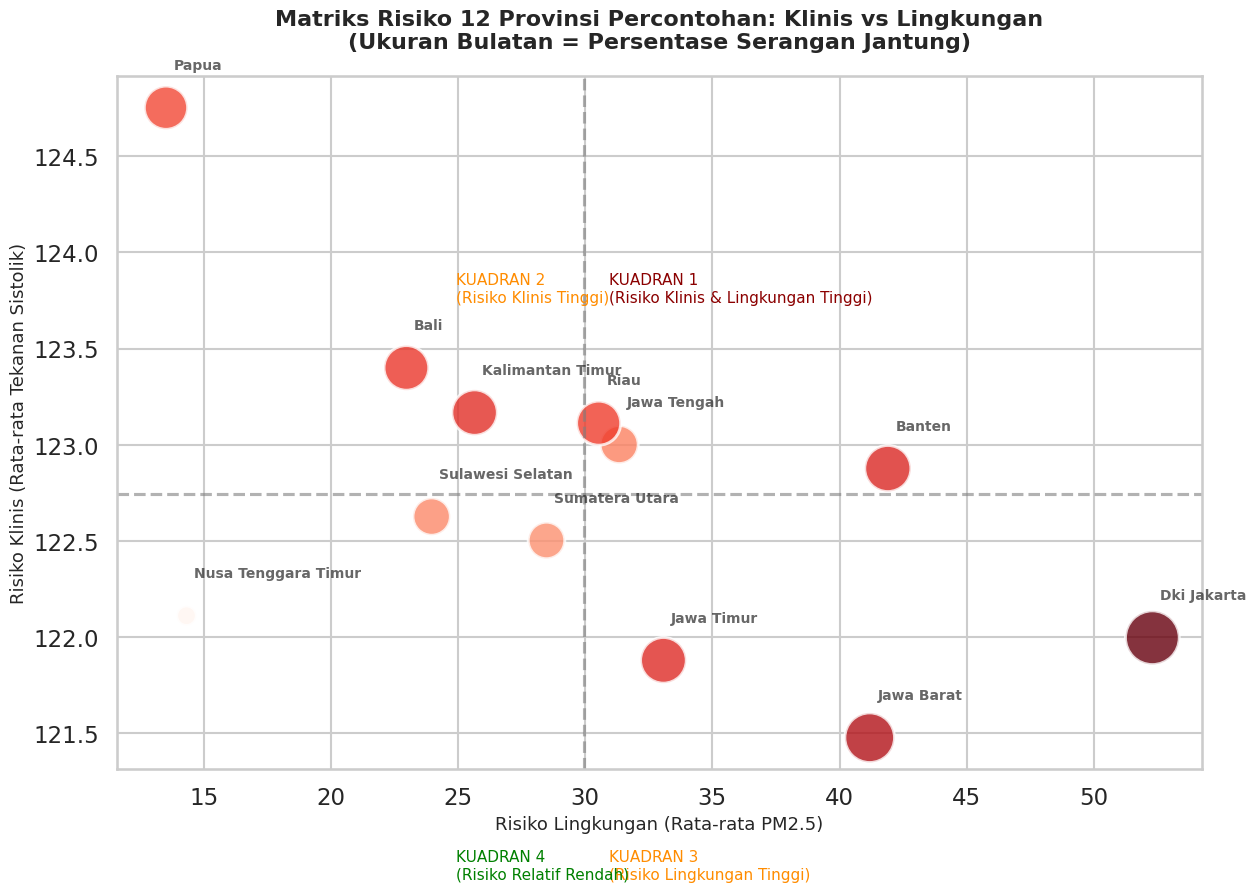

In [48]:
# Set tema visual
sns.set_theme(style="whitegrid", context="talk")

# 1. Menghitung Rata-rata Faktor Klinis & Lingkungan per Provinsi
prov_summary = df.groupby('provinsi').agg(
    avg_pm25=('paparan_pm25', 'mean'),            # Sumbu X (Lingkungan)
    avg_sistolik=('tekanan_sistolik', 'mean'),    # Sumbu Y (Klinis)
    kasus_jantung_persen=('serangan_jantung', 'mean') # Ukuran Gelembung
).reset_index()

# Mengubah proporsi menjadi persentase untuk kasus jantung
prov_summary['kasus_jantung_persen'] = prov_summary['kasus_jantung_persen'] * 100

# 2. Membuat Scatter Plot (Kuadran Matriks)
plt.figure(figsize=(14, 9))
scatter = sns.scatterplot(
    data=prov_summary, 
    x='avg_pm25', 
    y='avg_sistolik', 
    size='kasus_jantung_persen', 
    hue='kasus_jantung_persen',
    sizes=(200, 1500), # Ukuran gelembung mencerminkan tingkat serangan jantung
    palette='Reds',    # Warna merah semakin gelap = kasus semakin banyak
    alpha=0.8,
    legend=False
)

# 3. Menambahkan Nama 12 Provinsi di dekat gelembung
for i in range(prov_summary.shape[0]):
    plt.text(
        prov_summary['avg_pm25'][i] + 0.3, 
        prov_summary['avg_sistolik'][i] + 0.2, 
        prov_summary['provinsi'][i].title(), 
        fontsize=10, 
        fontweight='bold',
        alpha=0.7
    )

# 4. Membuat Garis Kuadran (Berdasarkan nilai rata-rata dari 12 provinsi tersebut)
batas_x = prov_summary['avg_pm25'].mean()
batas_y = prov_summary['avg_sistolik'].mean()
plt.axvline(batas_x, color='gray', linestyle='--', alpha=0.6)
plt.axhline(batas_y, color='gray', linestyle='--', alpha=0.6)

# 5. Anotasi Label Kuadran
plt.text(batas_x + 1, batas_y + 1, 'KUADRAN 1\n(Risiko Klinis & Lingkungan Tinggi)', color='darkred', fontsize=11)
plt.text(batas_x - 5, batas_y + 1, 'KUADRAN 2\n(Risiko Klinis Tinggi)', color='darkorange', fontsize=11)
plt.text(batas_x + 1, batas_y - 2, 'KUADRAN 3\n(Risiko Lingkungan Tinggi)', color='darkorange', fontsize=11)
plt.text(batas_x - 5, batas_y - 2, 'KUADRAN 4\n(Risiko Relatif Rendah)', color='green', fontsize=11)

plt.title('Matriks Risiko 12 Provinsi Percontohan: Klinis vs Lingkungan\n(Ukuran Bulatan = Persentase Serangan Jantung)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Risiko Lingkungan (Rata-rata PM2.5)', fontsize=13)
plt.ylabel('Risiko Klinis (Rata-rata Tekanan Sistolik)', fontsize=13)

# Simpan grafik resolusi tinggi untuk proposal
plt.savefig('matriks_dispatch_12provinsi.png', dpi=300, bbox_inches='tight')
plt.show()

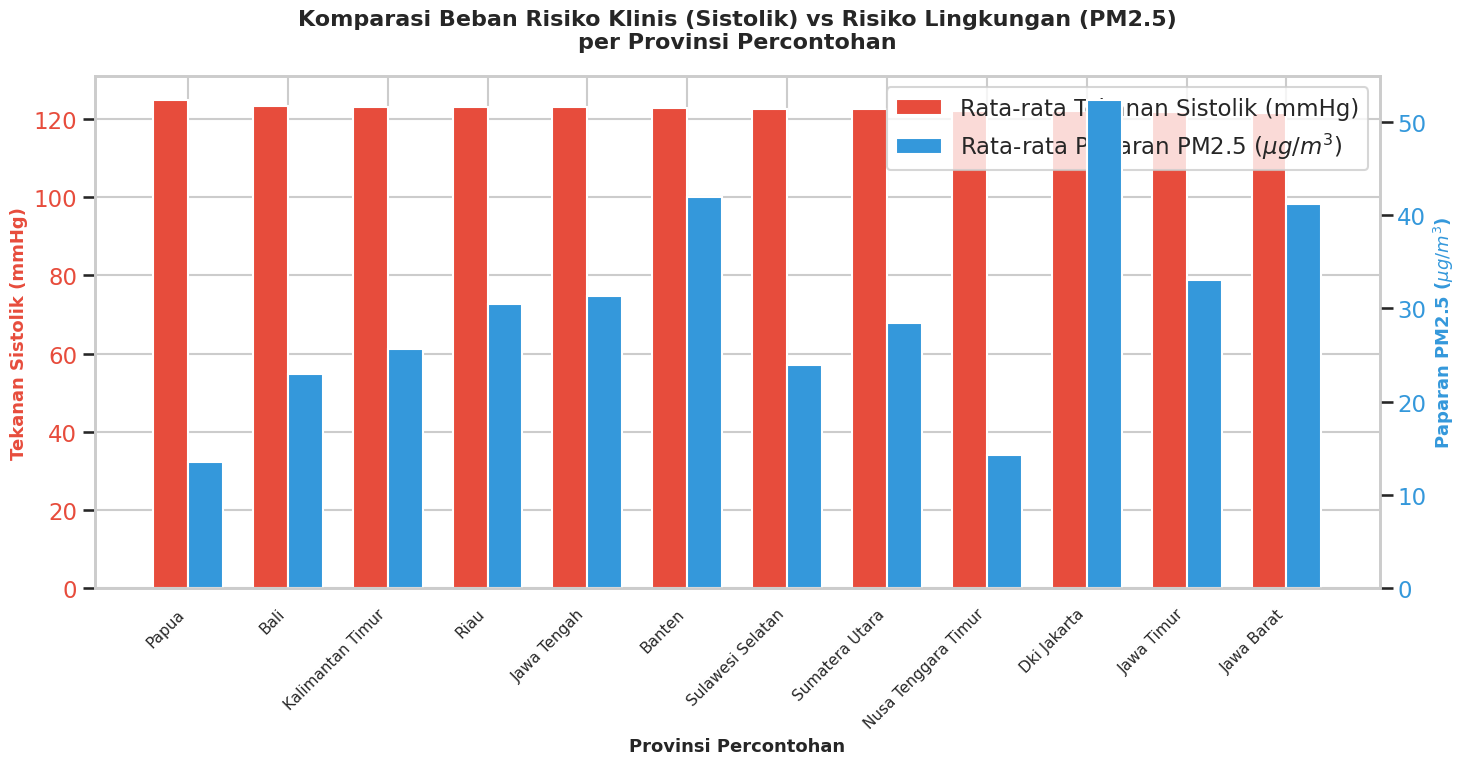

In [50]:
# Set tema visual
sns.set_theme(style="whitegrid", context="talk")

# 1. Menyiapkan data per provinsi (mengambil rata-rata dari df yang sudah bersih)
bar_data = df.groupby('provinsi').agg(
    avg_sistolik=('tekanan_sistolik', 'mean'),
    avg_pm25=('paparan_pm25', 'mean')
).reset_index()

# Mengurutkan provinsi berdasarkan tekanan sistolik tertinggi agar grafik rapi
bar_data = bar_data.sort_values(by='avg_sistolik', ascending=False)

# 2. Mengatur ukuran canvas untuk 2 bar chart berdampingan (atau normalized bar)
fig, ax1 = plt.subplots(figsize=(15, 8))

# Pengaturan posisi sumbu X untuk bar ganda
x = np.arange(len(bar_data['provinsi']))
width = 0.35

# Membuat Bar untuk Tekanan Sistolik (Sumbu Y kiri)
rects1 = ax1.bar(x - width/2, bar_data['avg_sistolik'], width, label='Rata-rata Tekanan Sistolik (mmHg)', color='#e74c3c')
ax1.set_ylabel('Tekanan Sistolik (mmHg)', color='#e74c3c', fontsize=13, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#e74c3c')

# Membuat Sumbu Y kedua untuk Paparan PM2.5 agar skala berbeda bisa ditampilkan bersamaan
ax2 = ax1.twinx()
# PERBAIKAN: Menambahkan 'r' sebelum string untuk mengatasi SyntaxWarning
rects2 = ax2.bar(x + width/2, bar_data['avg_pm25'], width, label=r'Rata-rata Paparan PM2.5 ($\mu g/m^3$)', color='#3498db')
ax2.set_ylabel(r'Paparan PM2.5 ($\mu g/m^3$)', color='#3498db', fontsize=13, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#3498db')
ax2.grid(False) # Menghindari tumpang tindih garis grid

# Penamaan label sumbu X (Provinsi)
ax1.set_xticks(x)
ax1.set_xticklabels(bar_data['provinsi'].str.title(), rotation=45, ha='right', fontsize=11)

plt.title('Komparasi Beban Risiko Klinis (Sistolik) vs Risiko Lingkungan (PM2.5)\nper Provinsi Percontohan', fontsize=16, fontweight='bold', pad=20)
ax1.set_xlabel('Provinsi Percontohan', fontsize=13, fontweight='bold')

# Menggabungkan legenda dari dua sumbu y
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('komparasi_klinis_pm25_provinsi.png', dpi=300, bbox_inches='tight')
plt.show()

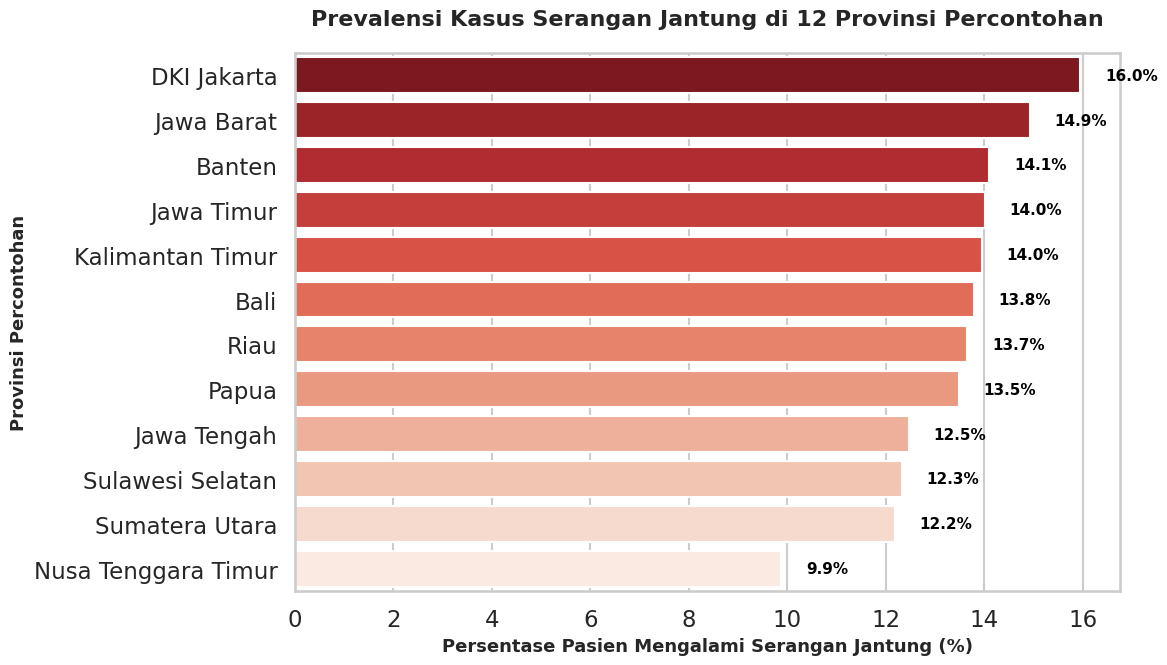

In [52]:
# Set tema visual
sns.set_theme(style="whitegrid", context="talk")

# 1. Menghitung persentase (proporsi) serangan jantung per provinsi
proporsi_jantung = df.groupby('provinsi')['serangan_jantung'].mean().reset_index()
proporsi_jantung['persen_serangan_jantung'] = proporsi_jantung['serangan_jantung'] * 100

# Mengurutkan dari persentase tertinggi ke terendah agar grafiknya mudah dibaca
proporsi_jantung = proporsi_jantung.sort_values(by='persen_serangan_jantung', ascending=False)

# 2. Membuat Bar Chart Horizontal
plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=proporsi_jantung, 
    y='provinsi', 
    x='persen_serangan_jantung', 
    hue='provinsi',        # PERBAIKAN: Menambahkan argumen hue
    palette='Reds_r',      # Warna merah gradasi, semakin gelap semakin tinggi persentasenya
    legend=False           # PERBAIKAN: Mematikan legenda agar grafik tetap bersih
)

# Menambahkan label angka di ujung batang grafik agar informatif
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:.1f}%',
                (width + 0.5, p.get_y() + p.get_height() / 2.),
                ha='left', va='center',
                fontsize=11, fontweight='bold', color='black')

plt.title('Prevalensi Kasus Serangan Jantung di 12 Provinsi Percontohan', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Persentase Pasien Mengalami Serangan Jantung (%)', fontsize=13, fontweight='bold')
plt.ylabel('Provinsi Percontohan', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('prevalensi_serangan_jantung_provinsi.png', dpi=300, bbox_inches='tight')
plt.show()